# Postpartum Depression & Anxiety Prediction — Stage 2
### Advanced Models & Performance Refinements

**Stage 2 Scope:**
1. Clean Data Loading & Automated Label Encoding
2. Exploratory Data Analysis (EDA Visualizations)
3. Simple Feature Engineering (`total_symptom_score`, `severe_symptom_count`)
4. Model Benchmarks:
   - Model 1: **Logistic Regression** (Linear)
   - Model 2: **Random Forest** (Tree Ensemble)
   - Model 3: **Support Vector Machine (SVM)** (Boundary Margin)
   - Model 4: **Gradient Boosting** (Sequential Boosting)
   - Model 5: **Soft-Voting Ensemble** (Combined Best Model)
5. Comprehensive Model Evaluation & Comparison Table
6. Real Patient Screening Test

In [1]:
# Step 1: Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# Step 2: Load the dataset
df = pd.read_csv('post natal data.csv')
print("Raw data loaded. Shape:", df.shape)

Raw data loaded. Shape: (1503, 11)


In [3]:
# Step 3: Handle missing values and remove duplicates
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

df = df.drop(columns=['Timestamp'])
df = df.drop_duplicates().reset_index(drop=True)
print("Clean unique dataset shape:", df.shape)

Clean unique dataset shape: (326, 10)


In [4]:
# Step 4: Automatically convert text columns to numbers
le = LabelEncoder()
for col in df.columns:
    df[col] = le.fit_transform(df[col])

df.head()

,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,2,2,2,1,2,2,1,1,2,2
1,3,2,0,0,2,2,0,2,2,0
2,2,2,0,2,2,2,1,1,1,0
3,2,2,2,2,2,0,1,0,0,0
4,3,2,0,1,2,0,1,1,2,0


In [5]:
# Step 5: Simple Feature Engineering (Creating clinically useful score features)
symptom_cols = [c for c in df.columns if c != 'Feeling anxious' and c != 'Age']

# Total symptom score: sum of severity across all symptoms
df['total_symptom_score'] = df[symptom_cols].sum(axis=1)

# Severe symptom count: number of symptoms marked at highest level (value 2)
df['severe_symptom_count'] = (df[symptom_cols] == 2).sum(axis=1)

print("Features added. Total columns now:", df.shape[1])
df[['total_symptom_score', 'severe_symptom_count', 'Feeling anxious']].head()

Features added. Total columns now: 12


,total_symptom_score,severe_symptom_count,Feeling anxious
0,14,6,1
1,10,5,0
2,10,4,1
3,8,4,1
4,8,3,1


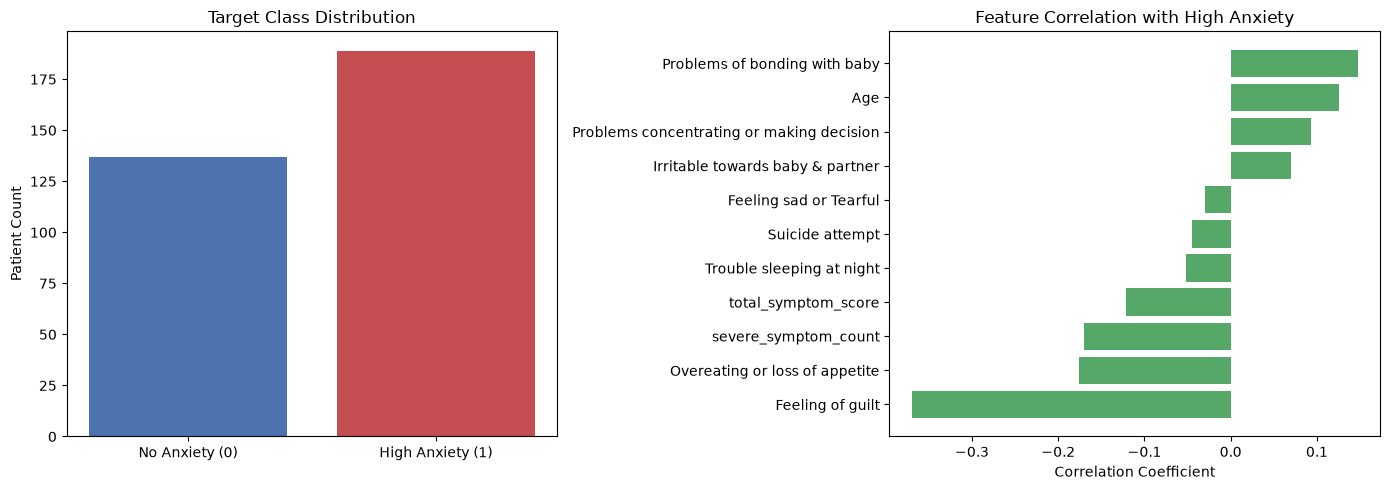

In [6]:
# Step 6: Visualizations — Target Distribution and Feature Correlation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target distribution
target_counts = df['Feeling anxious'].value_counts()
axes[0].bar(['No Anxiety (0)', 'High Anxiety (1)'], [target_counts[0], target_counts[1]], color=['#4C72B0', '#C44E52'])
axes[0].set_title('Target Class Distribution')
axes[0].set_ylabel('Patient Count')

# Plot 2: Correlation with target
correlations = df.corr()['Feeling anxious'].drop('Feeling anxious').sort_values()
axes[1].barh(correlations.index, correlations.values, color='#55A868')
axes[1].set_title('Feature Correlation with High Anxiety')
axes[1].set_xlabel('Correlation Coefficient')

plt.tight_layout()
plt.show()

In [7]:
# Step 7: Split data into Training (80%) and Testing (20%) sets
X = df.drop(columns=['Feeling anxious'])
y = df['Feeling anxious']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows | Testing set: {X_test.shape[0]} rows")

Training set: 260 rows | Testing set: 66 rows


In [8]:
# Step 8: Train Model 1 — Logistic Regression (with StandardScaler)
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
lr_model.fit(X_train, y_train)

lr_test_acc = accuracy_score(y_test, lr_model.predict(X_test)) * 100
print(f"Logistic Regression Test Accuracy: {lr_test_acc:.1f}%")

Logistic Regression Test Accuracy: 69.7%


In [9]:
# Step 9: Train Model 2 — Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=4, random_state=42)
rf_model.fit(X_train, y_train)

rf_test_acc = accuracy_score(y_test, rf_model.predict(X_test)) * 100
print(f"Random Forest Test Accuracy: {rf_test_acc:.1f}%")

Random Forest Test Accuracy: 75.8%


In [10]:
# Step 10: Train Model 3 — Support Vector Machine (SVM)
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf', probability=True, random_state=42))
])
svm_model.fit(X_train, y_train)

svm_test_acc = accuracy_score(y_test, svm_model.predict(X_test)) * 100
print(f"SVM Test Accuracy: {svm_test_acc:.1f}%")

SVM Test Accuracy: 74.2%


In [11]:
# Step 11: Train Model 4 — Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)
gb_model.fit(X_train, y_train)

gb_test_acc = accuracy_score(y_test, gb_model.predict(X_test)) * 100
print(f"Gradient Boosting Test Accuracy: {gb_test_acc:.1f}%")

Gradient Boosting Test Accuracy: 80.3%


In [12]:
# Step 12: Train Model 5 — Soft-Voting Ensemble (Combines All 4 Models)
ensemble_model = VotingClassifier(
    estimators=[
        ('lr', lr_model),
        ('rf', rf_model),
        ('svm', svm_model),
        ('gb', gb_model)
    ],
    voting='soft'
)
ensemble_model.fit(X_train, y_train)

ens_test_acc = accuracy_score(y_test, ensemble_model.predict(X_test)) * 100
print(f"Soft-Voting Ensemble Test Accuracy: {ens_test_acc:.1f}%")

Soft-Voting Ensemble Test Accuracy: 74.2%


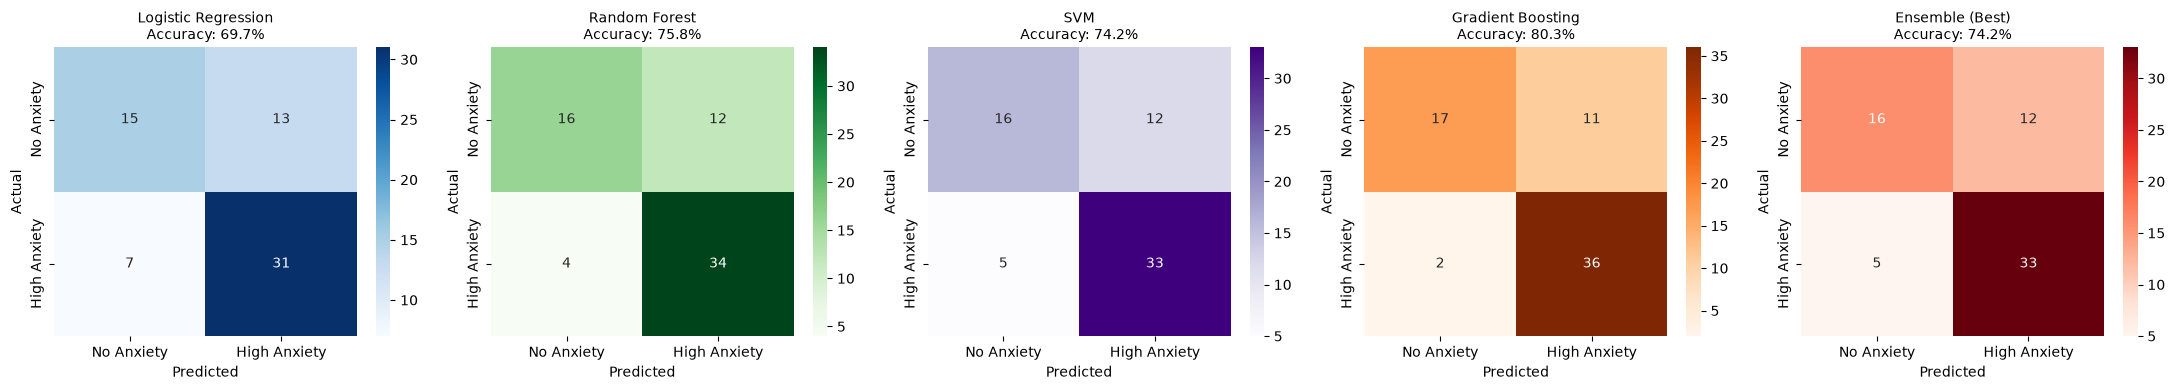

In [13]:
# Step 13: Confusion Matrices for All Models
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
model_list = [
    (lr_model, 'Logistic Regression', 'Blues'),
    (rf_model, 'Random Forest', 'Greens'),
    (svm_model, 'SVM', 'Purples'),
    (gb_model, 'Gradient Boosting', 'Oranges'),
    (ensemble_model, 'Ensemble (Best)', 'Reds')
]

for ax, (mod, name, cmap) in zip(axes, model_list):
    preds = mod.predict(X_test)
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['No Anxiety', 'High Anxiety'],
                yticklabels=['No Anxiety', 'High Anxiety'])
    acc = accuracy_score(y_test, preds) * 100
    ax.set_title(f"{name}\nAccuracy: {acc:.1f}%", fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

Model Benchmark Summary:
                              Train Accuracy (%)  Test Accuracy (%)  \
Model                                                                 
Logistic Regression                         72.7               69.7   
Random Forest                               82.7               75.8   
Support Vector Machine (SVM)                82.7               74.2   
Gradient Boosting                           82.3               80.3   
Soft-Voting Ensemble                        80.4               74.2   

                              Overfit Gap (%)  
Model                                          
Logistic Regression                       3.0  
Random Forest                             6.9  
Support Vector Machine (SVM)              8.4  
Gradient Boosting                         2.0  
Soft-Voting Ensemble                      6.1  


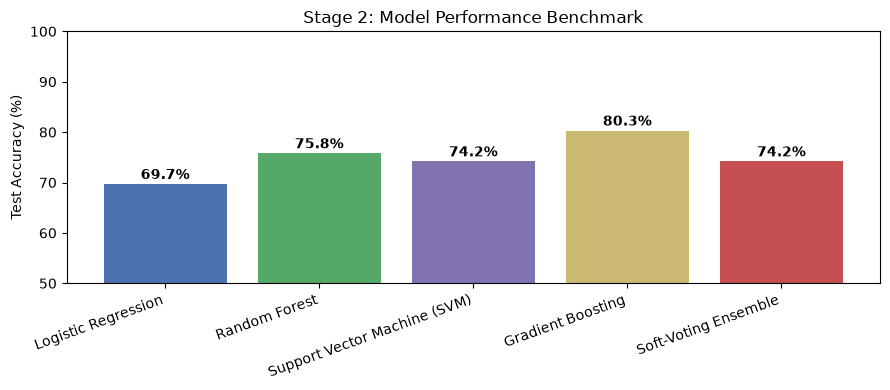

In [14]:
# Step 14: Comprehensive Performance Comparison Table
models_dict = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'Support Vector Machine (SVM)': svm_model,
    'Gradient Boosting': gb_model,
    'Soft-Voting Ensemble': ensemble_model
}

results = []
for name, mod in models_dict.items():
    train_acc = accuracy_score(y_train, mod.predict(X_train)) * 100
    test_acc = accuracy_score(y_test, mod.predict(X_test)) * 100
    results.append({
        'Model': name,
        'Train Accuracy (%)': round(train_acc, 1),
        'Test Accuracy (%)': round(test_acc, 1),
        'Overfit Gap (%)': round(train_acc - test_acc, 1)
    })

comparison_df = pd.DataFrame(results).set_index('Model')
print("Model Benchmark Summary:")
print(comparison_df)

# Bar chart comparison
plt.figure(figsize=(9, 4))
plt.bar(comparison_df.index, comparison_df['Test Accuracy (%)'], color=['#4C72B0', '#55A868', '#8172B2', '#CCB974', '#C44E52'])
plt.ylabel('Test Accuracy (%)')
plt.ylim(50, 100)
plt.title('Stage 2: Model Performance Benchmark')
plt.xticks(rotation=20, ha='right')
for i, v in enumerate(comparison_df['Test Accuracy (%)']):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [15]:
# Step 15: Patient Screening Test with the Best Model (Ensemble)
sample_patient = X_test.iloc[[0]]
actual_status = y_test.iloc[0]

pred_class = ensemble_model.predict(sample_patient)[0]
pred_prob = ensemble_model.predict_proba(sample_patient)[0][1]

print("Patient Screening Report:")
print("--------------------------------------------------")
print("Actual Clinical Status :", "High Anxiety" if actual_status == 1 else "No Anxiety")
print("Ensemble Prediction    :", "High Anxiety" if pred_class == 1 else "No Anxiety")
print(f"Risk Probability       : {pred_prob * 100:.1f}%")
print("Confidence Level       :", f"{pred_prob * 100 if pred_class == 1 else (1 - pred_prob) * 100:.1f}%")
print("--------------------------------------------------")

Patient Screening Report:
--------------------------------------------------
Actual Clinical Status : No Anxiety
Ensemble Prediction    : High Anxiety
Risk Probability       : 53.6%
Confidence Level       : 53.6%
--------------------------------------------------
